In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import scipy
import scipy.spatial
import scipy.spatial.distance


In [2]:
with open("X.trc", "rb") as f:
    X = torch.load(f)
with open("Y.trc", "rb") as f:
    Y = torch.load(f)
X = X.numpy()
Y = Y.numpy()

In [3]:
print(X.shape)
print(Y.shape)

(238599, 24)
(238599, 720)


In [4]:
# samples = np.random.choice(X.shape[0], size=50000, replace=False)
# X_sub = X[samples]
# Y_sub = Y[samples]

X_sub = X
Y_sub = Y

In [5]:
multiplier = np.array([1] * 12 + [1] * 12)

In [6]:
r = 0.5777829296876128

In [7]:
def compute_diff(X_data, Y_data):
    x_diff = np.ndarray(X_data.shape[0])
    y_diff = np.ndarray(X_data.shape[0])

    tree = scipy.spatial.KDTree(X_data)
    indices = tree.query_ball_point(X_data, r * 1.1, workers=-1)
    for i, index in enumerate(indices):
        x_diff[i] = np.linalg.norm(X_data[index].mean(0) - X_data[i])
        y_diff[i] = np.linalg.norm(Y_data[index].mean(0) - Y_data[i])

    return np.array(x_diff).flatten(), np.array(y_diff).flatten()

In [8]:
X_data, Y_data = X_sub, Y_sub
cum = 1
for i in range(30, 8, -1):
    x_diff, y_diff = compute_diff(X_data, Y_data)
    condition = y_diff < i
    X_data, Y_data = X_data[condition], Y_data[condition]
    cum *= condition.mean()
    print(i, cum, condition.mean())

30 0.9951005662219875 0.9951005662219875
29 0.9930008088885536 0.9978899043928737
28 0.990859140231099 0.9978432357372884
27 0.9883402696574587 0.997457892377061
26 0.9850460395894366 0.9966669069659948
25 0.9812614470303731 0.9961579536316486
24 0.9768104644193815 0.9954640196815417
23 0.9714919174011626 0.9945551903752585
22 0.9651633074740463 0.9934856792797145
21 0.9581976454218164 0.9927829187057888
20 0.9499662613841632 0.9914095133952979
19 0.9405823159359424 0.9901218118688261
18 0.9306367587458453 0.9894261703398063
17 0.9200415760334282 0.9886151254903197
16 0.9080255994367115 0.9869397460835182
15 0.8954102909064997 0.9861068800945286
14 0.882665057271824 0.9857660407032259
13 0.869177993201983 0.984720065716063
12 0.8548485115193272 0.9835137546109892
11 0.8407411598539807 0.9834972495415902
10 0.8258668309590566 0.982308075772682
9 0.8107452252524107 0.981690019335096


In [12]:
x_diff, y_diff = compute_diff(X_data, Y_data)
condition = y_diff < 6
X_data, Y_data = X_data[condition], Y_data[condition]
cum *= condition.mean()
print(i, cum, condition.mean())

9 0.6948520320705449 0.9134691673645701


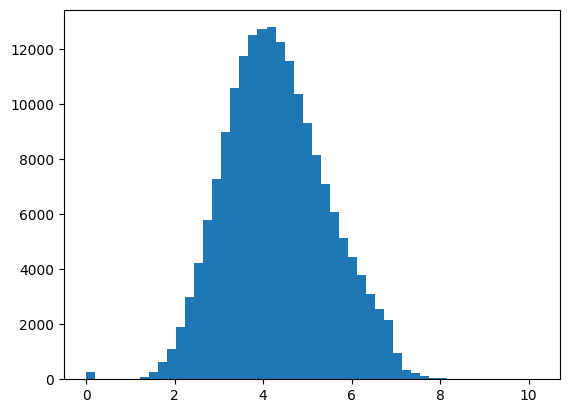

165791


In [13]:
plt.hist(y_diff, bins=50)
plt.show()
print(len(X_data))
with open("X_filtered.trc", "wb") as f:
    torch.save(torch.tensor(X_data), f)
with open("Y_filtered.trc", "wb") as f:
    torch.save(torch.tensor(Y_data), f)

10930
1.0


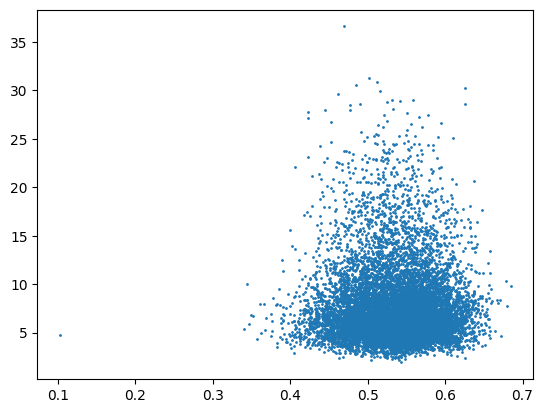

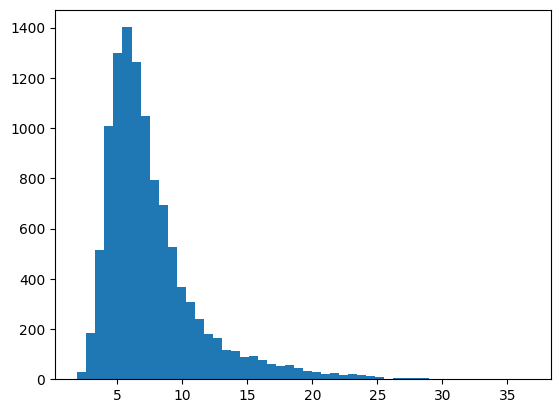

In [11]:
x_diff, y_diff = compute_diff(X, Y)

condition = y_diff < 100
X_data, Y_data = torch.tensor(X[condition]), torch.tensor(Y[condition])
print(len(X_data))
print(condition.mean())

plt.scatter(x_diff[condition], y_diff[condition], s=1)
plt.show()

plt.hist(y_diff[condition], bins=50)
plt.show()


# with open("X_filtered.trc", "wb") as f:
#     torch.save(torch.tensor(X[condition]), f)
# with open("Y_filtered.trc", "wb") as f:
#     torch.save(torch.tensor(Y[condition]), f)


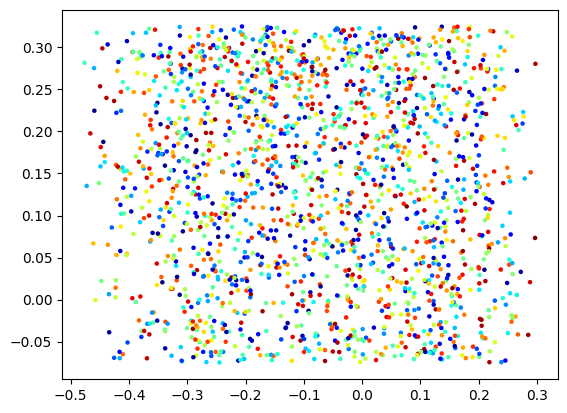

In [27]:
for i in range(0, 1):
    x = []
    y = []
    # z = []
    c = []
    for x_val, y_val in zip(X[condition], Y[condition]):
        x.append(x_val[0])
        y.append(x_val[1])
        # z.append(x_val[2])
        c.append(y_val[i])

    fig = plt.figure()
    ax = fig.add_subplot()
    ax.scatter(x, y, c=c, alpha=1, s=5, cmap="jet")
    # plt.savefig(f"test_{i}.png", dpi=1000)
    plt.show()

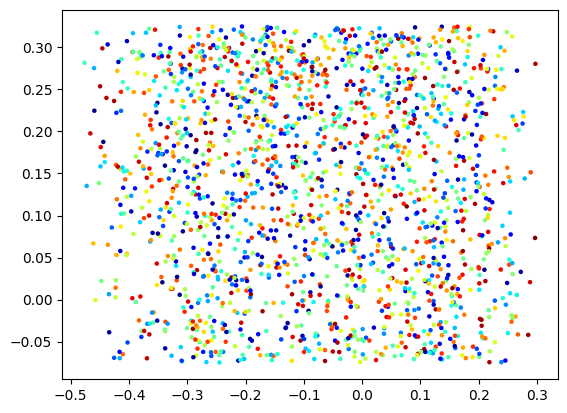

In [28]:
for i in range(0, 1):
    x = []
    y = []
    # z = []
    c = []
    for x_val, y_val in zip(X, Y):
        x.append(x_val[0])
        y.append(x_val[1])
        # z.append(x_val[2])
        c.append(y_val[i])

    fig = plt.figure()
    ax = fig.add_subplot()
    ax.scatter(x, y, c=c, alpha=1, s=5, cmap="jet")
    # plt.savefig(f"test_{i}.png", dpi=1000)
    plt.show()